<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/kinetic_theory/kintheory_ch4_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Kinetic Theory* — `kintheory_ch4_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Kinetic Theory — Chapter 4: Linear Response
## Figure Generation Notebook (Revised)

**PSE Lab** | Based on Tong, *Kinetic Theory* (DAMTP)

All figures are saved to `figures/` and match the `<img src=...>` references in the
Quarto revealjs slides.

| Figure file | Slide | Content |
|---|---|---|
| `kt_fig_kramerskronig.png` | Kramers–Kronig slide | PV kernel + δ-function limit (multi-ε) |
| `kt_fig_chi_harmonic.png` | Reactive/Dissipative slide | χ'(ω) and χ''(ω) with annotated features |
| `kt_fig_dissipation.png` | Dissipation slide | Power absorbed — log scale + inset |
| `kt_fig_poles.png` | Pole locations slide | Complex ω-plane, well-separated poles |
| `kt_fig_spectral.png` | Spectral function slide | Discrete↔continuum, explicit odd symmetry |


## 0. Setup — dark theme matching `kintheory_slides.css`

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import os

os.makedirs('figures', exist_ok=True)

# ── Colour palette (from kintheory_slides.css) ────────────────────────────
BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
TEAL    = '#2dd4bf'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

def dark_ax(ax, grid=True):
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=10)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(TEAL)
    for sp in ax.spines.values():
        sp.set_edgecolor(BORDER)
    ax.axhline(0, color=BORDER, lw=0.8, zorder=0)
    if grid:
        ax.grid(True, color=BORDER, lw=0.5, alpha=0.5, zorder=0)

def save_fig(fig, fname, dpi=150):
    path = f'figures/{fname}'
    fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor=BG)
    plt.close(fig)
    print(f'✓  Saved {path}')

print('Setup complete.')


Setup complete.


---
## Figure 1 — Kramers–Kronig: Principal-Value Kernel & δ-function Limit

**Physical content:** Equation (4.11) in Tong decomposes $\frac{1}{\omega'-\omega\mp i\epsilon}$:

$$\frac{1}{\omega'-(\omega\pm i\epsilon)} = \underbrace{\frac{\omega'-\omega}{(\omega'-\omega)^2+\epsilon^2}}_{\text{Re: principal-value kernel}} \pm \underbrace{\frac{i\epsilon}{(\omega'-\omega)^2+\epsilon^2}}_{\text{Im: Lorentzian}\;\to\;\delta(\omega'-\omega)}$$

**Improvements over v1:**
- Symmetric x-axis centred on the pole $\omega=1$ → odd symmetry of Re part clearly visible
- Multiple $\epsilon$ values overlaid on Im panel → $\epsilon\to 0$ limiting process visible
- Shaded area under the Lorentzian normalised to show constant area = $\pi$ for all $\epsilon$
- Annotation connects to Kramers–Kronig: "knowing Im $\Rightarrow$ knowing Re"


In [2]:
# ── FIG 1  Kramers-Kronig ─────────────────────────────────────────────────
omega_pole = 1.0
x_range    = 3.5
wp = np.linspace(omega_pole - x_range, omega_pole + x_range, 4000)
epsilons   = [0.5, 0.25, 0.1, 0.03]
eps_colors = [BLUE, TEAL, ORANGE, RED]
eps_alphas = [0.55, 0.70, 0.85, 1.00]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)
for ax in (ax1, ax2):
    dark_ax(ax)

eps_pv   = 0.05
denom_pv = (wp - omega_pole)**2 + eps_pv**2
real_pv  = (wp - omega_pole) / denom_pv
mask     = np.abs(wp - omega_pole) > 3 * eps_pv
ax1.plot(wp[mask], real_pv[mask], color=TEAL, lw=2.2)
ax1.fill_between(wp, real_pv, 0,
                 where=(wp > omega_pole + 3*eps_pv), alpha=0.12, color=TEAL)
ax1.fill_between(wp, real_pv, 0,
                 where=(wp < omega_pole - 3*eps_pv), alpha=0.12, color=RED)
ax1.axvline(omega_pole, color=RED, lw=1.0, ls='--', alpha=0.65,
            label=f'pole  $\\omega={omega_pole}$')
ax1.set_xlim(omega_pole - x_range, omega_pole + x_range)
ax1.set_ylim(-2.2, 2.2)
ax1.set_xlabel("$\\omega'$", fontsize=13)
ax1.set_ylabel("$\\mathrm{Re}\\;[1/(\\omega'-\\omega-i\\epsilon)]$", fontsize=11)
ax1.set_title('Principal-Value Kernel', fontsize=12)
ax1.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
# text in top-left blank region — no curve there
ax1.text(omega_pole - x_range + 0.1, 1.80,
         'odd function:\n$f(\\omega_0+\\Delta) = -f(\\omega_0-\\Delta)$',
         color=MUTED, fontsize=8.5)
ax1.text(omega_pole - x_range + 0.1, -2.02,
         '$\\mathcal{P}$ integral: knowing $\\chi\'\'$ determines $\\chi\'$',
         color=MUTED, fontsize=8, style='italic')

for eps, col, alph in zip(epsilons, eps_colors, eps_alphas):
    denom = (wp - omega_pole)**2 + eps**2
    ax2.plot(wp, eps / denom, color=col, lw=1.8, alpha=alph,
             label=f'$\\epsilon = {eps}$')
denom0   = (wp - omega_pole)**2 + epsilons[-1]**2
lorentz0 = epsilons[-1] / denom0
ax2.fill_between(wp, lorentz0, alpha=0.15, color=RED)
ax2.axvline(omega_pole, color=RED, lw=1.0, ls='--', alpha=0.65)
ax2.set_xlim(omega_pole - x_range, omega_pole + x_range)
ax2.set_ylim(-0.5, (1 / epsilons[-1]) * 1.15)
ax2.set_xlabel("$\\omega'$", fontsize=13)
ax2.set_ylabel("$\\mathrm{Im}\\;[1/(\\omega'-\\omega-i\\epsilon)]$", fontsize=11)
# corrected delta argument
ax2.set_title(r"Lorentzian $\to\delta(\omega'-\omega)$ as $\epsilon\to 0$",
              fontsize=12)
ax2.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER,
           loc='upper right')
peak_height = 1 / epsilons[-1]
# "Area = pi" to the right of the peak — clear horizontal space
ax2.text(omega_pole + 1.3, peak_height * 0.55,
         'Area $= \\pi$\nfor all $\\epsilon$',
         color=MUTED, fontsize=9, ha='left')
ax2.text(omega_pole - x_range + 0.1, peak_height * 0.04,
         r"$\epsilon\to 0\;\Rightarrow\;\delta(\omega'-\omega)$",
         color=MUTED, fontsize=8.5, style='italic')

fig.suptitle(
    r"Kramers-Kronig: decomposition of $1/(\omega' - \omega \mp i\epsilon)$",
    color=TEXT, fontsize=13, y=1.01)
fig.tight_layout()
save_fig(fig, 'kt_fig_kramerskronig.png')

✓  Saved figures/kt_fig_kramerskronig.png


---
## Figure 2 — Response Function of the Damped Harmonic Oscillator

$$\chi(\omega) = \frac{1}{\omega_0^2 - \omega^2 - i\gamma\omega}, \quad \omega_0=1,\;\gamma=0.5$$

**Physical features to communicate clearly:**
1. $\chi'(0) = 1/\omega_0^2$ — static susceptibility (reactive part at $\omega=0$)
2. $\chi'(\omega)$ is **even** — sign change near $\pm\omega_0$
3. $\chi''(\omega)$ is **odd** — positive absorption only for $\omega>0$
4. $\chi''$ peaks near $\pm\omega_0$ (where energy can be absorbed)
5. Same y-scale for both panels enables comparison

**Improvements over v1:**
- Shared y-axis range (both panels ±2.5)
- Explicit marker at $\omega=0$ for $\chi'(0)=1/\omega_0^2$
- Annotations on both ±ω₀ peaks for χ''
- Colour-coded even/odd labels


In [3]:
# ── FIG 2  chi' and chi'' ─────────────────────────────────────────────────
omega0 = 1.0; gam = 0.5
omegas = np.linspace(-4, 4, 5000)
D2     = (omega0**2 - omegas**2)**2 + (gam * omegas)**2
chi_re = (omega0**2 - omegas**2) / D2
chi_im = gam * omegas / D2
y_lim  = 2.5

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                gridspec_kw={'hspace': 0.12})
fig.patch.set_facecolor(BG)
for ax in (ax1, ax2):
    dark_ax(ax)

ax1.plot(omegas, chi_re, color=TEAL, lw=2.2, zorder=3)
ax1.scatter([0], [1/omega0**2], s=80, color=GREEN, zorder=5)
ax1.annotate(f'$\\chi\'(0) = 1/\\omega_0^2 = {1/omega0**2:.1f}$\n(static susceptibility)',
             xy=(0, 1/omega0**2), xytext=(0.4, 1.85), fontsize=9, color=GREEN,
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.2))
ax1.axvline( omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
ax1.axvline(-omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
ax1.text( omega0 + 0.08, -2.3, '$+\\omega_0$', color=MUTED, fontsize=9)
ax1.text(-omega0 + 0.08, -2.3, '$-\\omega_0$', color=MUTED, fontsize=9)
ax1.set_ylabel("$\\chi'(\\omega)$", fontsize=13)
ax1.set_ylim(-y_lim, y_lim)
ax1.set_title(
    "Reactive part $\\chi'(\\omega)$ — even:  $\\chi'(-\\omega)=+\\chi'(\\omega)$",
    fontsize=11)
ax1.text(3.0, 0.15, '$\\to 0$ as $\\omega\\to\\infty$', color=MUTED, fontsize=8.5)

ax2.plot(omegas, chi_im, color=ORANGE, lw=2.2, zorder=3)
ax2.fill_between(omegas, chi_im, 0, where=(omegas > 0), alpha=0.13, color=ORANGE)
ax2.fill_between(omegas, chi_im, 0, where=(omegas < 0), alpha=0.13, color=RED)
ax2.axvline( omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
ax2.axvline(-omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)

peak_val = 1.0 / (gam * omega0)
ax2.annotate('$\\chi\'\'(\\omega_0) = 1/\\gamma\\omega_0$\n(max absorption)',
             xy=(omega0, peak_val * 0.98), xytext=(2.2, 1.70),
             fontsize=9, color=ORANGE,
             arrowprops=dict(arrowstyle='->', color=ORANGE, lw=1.2))
ax2.annotate('$\\chi\'\'(-\\omega_0)$\n(max emission)', xy=(-omega0, -peak_val * 0.98), xytext=(-2.8, -1.70),
             fontsize=9, color=RED,
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.2))
# odd label: far-right, above zero line — well clear of peak
ax2.text(3.8, -1.0,
         '$\\chi\'\'(-\\omega)=-\\chi\'\'(\\omega)$\n(odd function)',
         fontsize=8.5, color=MUTED, ha='right', va='top')
# region labels: inside fill regions at low-amplitude edges
ax2.text(0.70, 0.68, 'absorbed\n($\\omega > 0$)',
         transform=ax2.transAxes, fontsize=8.5, color=ORANGE, ha='left')
ax2.text(0.05, 0.22, 'released\n($\\omega < 0$)',
         transform=ax2.transAxes, fontsize=8.5, color=RED, ha='left')

ax2.set_xlabel('$\\omega$', fontsize=13)
ax2.set_ylabel("$\\chi''(\\omega)$", fontsize=13)
ax2.set_ylim(-y_lim, y_lim); ax2.set_xlim(-4, 4)
ax2.set_title(
    "Dissipative part $\\chi''(\\omega)$ — odd:  $\\chi''(-\\omega)=-\\chi''(\\omega)$",
    fontsize=11)
fig.suptitle(
    f'Damped Harmonic Oscillator response function:'
    f'  $\\omega_0={omega0}$,  $\\gamma={gam}$',
    color=TEXT, fontsize=13)
save_fig(fig, 'kt_fig_chi_harmonic.png')

✓  Saved figures/kt_fig_chi_harmonic.png


---
## Figure 3 — Power Absorbed vs. Driving Frequency

$$\left\langle\frac{dW}{dt}\right\rangle = \frac{2F_0^2\,\gamma\,\Omega^2}{(\omega_0^2-\Omega^2)^2+(\gamma\Omega)^2}$$

**Physical features:**
1. Peak at $\Omega = \omega_0$ (resonance) — maximum energy absorption
2. $\langle dW/dt\rangle \propto \Omega^2$ as $\Omega\to 0$ (power vanishes at DC)
3. Narrower peak = smaller γ = less damping = higher Q-factor
4. All curves collapse at high $\Omega$ (radiation resistance regime)

**Improvements over v1:**
- Log y-scale (main panel) so all four curves are readable simultaneously
- Linear inset near $\Omega\approx\omega_0$ to show peak shape clearly
- Annotation of $\Omega\to 0$ power law and Q-factor


In [4]:
# ── FIG 3  Power absorbed ─────────────────────────────────────────────────
Omega  = np.linspace(0.01, 3.5, 5000)
omega0 = 1.0; F0 = 1.0
gammas = [0.1, 0.3, 0.5, 1.0]
colors = [TEAL, BLUE, ORANGE, RED]

fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor(BG); dark_ax(ax)

for gam, col in zip(gammas, colors):
    D2    = (omega0**2 - Omega**2)**2 + (gam * Omega)**2
    power = 2 * F0**2 * gam * Omega**2 / D2

    power = np.nan_to_num(power, nan=1e-30, posinf=1e-30, neginf=1e-30)
    power = np.clip(power, 1e-30, None)
    ax.plot(Omega, power, color=col, lw=2.0, label=f'$\\gamma = {gam}$')
ax.set_yscale('log')

ax.axvline(omega0, color=MUTED, lw=1.0, ls='--', alpha=0.75, label='$\\Omega=\\omega_0$')

Omega_lo  = np.linspace(0.02, 0.30, 200)
power_law = 2 * 0.1 * Omega_lo**2 / omega0**4
ax.plot(Omega_lo, power_law, '--', color=TEAL, lw=1.0, alpha=0.6)
# slope annotation: right of the guide line, above the inset region
ax.text(0.38, 2 * 0.1 * 0.30**2 / omega0**4 * 1.6,
        '$\\propto\\Omega^2$ (DC limit)', color=TEAL, fontsize=9, alpha=0.9)
# Q label: clear of inset (inset is lower-right), placed upper-center
ax.text(1.08, 10.0, #,0.65,
        '$Q \\approx \\omega_0/\\gamma$\n(peak width $\\leftrightarrow$ damping)',
        color=MUTED, fontsize=9)

ax.set_xlabel('Driving frequency $\\Omega$', fontsize=13)
ax.set_ylabel('$\\langle dW/dt\\rangle / F_0^2$  (log scale)', fontsize=12)
ax.set_title('Power absorbed by damped harmonic oscillator  ($\\omega_0=1$)', fontsize=12)
ax.set_xlim(0, 3.5)
ax.legend(fontsize=11, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER,
          loc='upper right')

# inset: lower-RIGHT corner to avoid covering the ∝Ω² slope at small Ω
axins = inset_axes(ax, width='34%', height='44%',
                   bbox_to_anchor=(0.35, 0.05, 1, 1),
                   bbox_transform=ax.transAxes, loc='lower left')
axins.set_facecolor(SURFACE)
axins.tick_params(colors=MUTED, labelsize=8)
for sp in axins.spines.values():
    sp.set_edgecolor(BORDER)
Omega_ins = np.linspace(0.5, 1.5, 3000)
for gam, col in zip(gammas, colors):
    D2    = (omega0**2 - Omega_ins**2)**2 + (gam * Omega_ins)**2
    power = 2 * F0**2 * gam * Omega_ins**2 / D2
    axins.plot(Omega_ins, power, color=col, lw=1.8)
axins.axvline(omega0, color=MUTED, lw=0.8, ls='--', alpha=0.7)
axins.set_xlim(0.5, 1.5)
# removed x-axis label (was clipping); inset title suffices
axins.set_title('Near $\\omega_0$  (linear scale)', color=TEAL, fontsize=8.5)
axins.grid(True, color=BORDER, lw=0.5, alpha=0.5)
save_fig(fig, 'kt_fig_dissipation.png')

✓  Saved figures/kt_fig_dissipation.png


---
## Figure 4 — Pole Locations in the Complex ω-Plane

**Physical content:** causality requires all poles below the real axis.
Different physics sits at different locations:
- **Oscillator (underdamped):** $\omega_\star = \pm\tilde\omega - i\gamma/2$ (symmetric about imaginary axis)
- **Diffusion:** $\omega = -iDk^2$ (purely imaginary, on imaginary axis)
- **Damped sound:** $\omega \approx \pm v_s k - i\alpha k^2$ (close to real axis, symmetric)

**Improvements over v1:**
- Poles spread across distinct Im ω values → easy to distinguish
- Annotations placed without arrow crossings (one side per pole type)
- Real axis marked as "branch cut / spectral support" with physical meaning
- Upper half shaded strongly red; lower half clearly "allowed"
- Overdamped oscillator shown as bonus (both poles on imaginary axis)


In [5]:
# ── FIG 4  Pole locations ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 8))
fig.patch.set_facecolor(BG); ax.set_facecolor(SURFACE)
ax.fill_between([-4, 4], [0, 0], [4, 4],   alpha=0.10, color=RED,   zorder=0)
ax.fill_between([-4, 4], [-4,-4], [0, 0],  alpha=0.06, color=GREEN, zorder=0)
ax.axhline(0, color=BORDER, lw=1.4, zorder=1)
ax.axvline(0, color=BORDER, lw=1.2, zorder=1)
ax.grid(True, color=BORDER, lw=0.5, alpha=0.4, zorder=0)
for sp in ax.spines.values():
    sp.set_edgecolor(BORDER)

# 1. Damped sound
sr, si = 2.5, -0.15
ax.scatter([+sr, -sr], [si, si], s=220, color=RED, marker='x', linewidths=3.0, zorder=5)
# label above the markers, tucked left of the right pole
ax.text(sr - 0.15, si + 0.40,
        'Damped sound\n$\\omega \\approx \\pm v_s k - i\\alpha k^2$',
        color=RED, fontsize=9.5, ha='right', va='bottom')

# 2. Underdamped oscillator
om_t, im_osc = 1.6, -0.9
ax.scatter([+om_t, -om_t], [im_osc, im_osc],
           s=220, color=TEAL, marker='x', linewidths=3.0, zorder=5)
# label left of the right marker — stays inside the plot
ax.text(om_t +1.8, im_osc - 0.25,
        'Underdamped osc.\n$\\omega_\\star = \\pm\\tilde{\\omega} - i\\gamma/2$',
        color=TEAL, fontsize=9.5, ha='right', va='top')

# 3. Overdamped oscillator
r1, r2 = -0.88, -2.12
ax.scatter([0, 0], [r1, r2], s=220, color=PURPLE, marker='x', linewidths=3.0, zorder=5)
# label to the left of Im axis
ax.text(1, (r1 + r2) / 2,
        'Overdamped osc.\nboth poles on Im axis',
        color=PURPLE, fontsize=9.5, ha='right', va='center')

# 4. Diffusion
diff_im = -3.0
ax.scatter([0], [diff_im], s=220, color=ORANGE, marker='x', linewidths=3.0, zorder=5)
ax.text(-0.20, diff_im,
        r'Diffusion: $\omega = -iDk^2$',
        color=ORANGE, fontsize=9.5, ha='right', va='center')

ax.text(3.7,  3.7, 'Forbidden\n(causality)',
        color=RED,   fontsize=11, ha='right', va='top',    alpha=0.9)
ax.text(3.7, -3.7, 'Allowed\n(poles here)',
        color=GREEN, fontsize=11, ha='right', va='bottom', alpha=0.9)
# real-axis note: placed safely above the horizontal zero line
ax.text(-3.8, 0.22,
        'real axis: spectral weight',
        color=MUTED, fontsize=9, style='italic')

ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect('equal')
ax.set_xlabel(r'Re $\omega$', fontsize=13, color=TEXT)
ax.set_ylabel(r'Im $\omega$', fontsize=13, color=TEXT)
ax.tick_params(colors=MUTED, labelsize=10)
ax.set_title(r'Pole locations in the complex $\omega$-plane', fontsize=13, color=TEAL)
legend_els = [
    Line2D([0],[0], marker='x', color=RED,    markersize=12, lw=0, label='Damped sound'),
    Line2D([0],[0], marker='x', color=TEAL,   markersize=12, lw=0, label='Underdamped osc.'),
    Line2D([0],[0], marker='x', color=PURPLE, markersize=12, lw=0, label='Overdamped osc.'),
    Line2D([0],[0], marker='x', color=ORANGE, markersize=12, lw=0, label='Diffusion'),
]
ax.legend(handles=legend_els, fontsize=10, facecolor=SURFACE,
          labelcolor=TEXT, edgecolor=BORDER, loc='upper left')
save_fig(fig, 'kt_fig_poles.png')

✓  Saved figures/kt_fig_poles.png


---
## Figure 5 — Spectral Function: Discrete → Continuum

**Physical content (Tong §4.3.1):**

$$\chi''(\omega) \longrightarrow \sum_{m,n} \delta\!\left(\omega-(E_n-E_m)\right)\left(e^{-\beta E_m}-e^{-\beta E_n}\right)$$

Key properties:
1. **Odd function**: $\chi''(-\omega) = -\chi''(\omega)$ — positive for $\omega>0$ (absorption)
2. **Finite system**: isolated delta-function spikes at transition frequencies $E_n-E_m$
3. **Infinite system**: spikes merge → smooth function, dissipation at all $\omega$

**Improvements over v1:**
- Explicitly construct ±freq pairs so odd symmetry is visually obvious in the bar plot
- Colour scheme: teal for ω>0 (absorption), red for ω<0 (emission) — matching chi'' sign convention
- Continuum panel: enforce exact odd symmetry by odd-symmetrising the result
- Shared x-axis range and aligned y=0 baseline


In [6]:
# ── FIG 5  Spectral function ──────────────────────────────────────────────
np.random.seed(7); kT = 0.8
energies    = np.array([0.5, 1.2, 2.0, 3.1, 4.5])
n_lev       = len(energies)
pos_freqs   = []; pos_weights = []
for m in range(n_lev):
    for n in range(m + 1, n_lev):
        Delta = energies[n] - energies[m]
        A     = (np.exp(-energies[m] / kT) - np.exp(-energies[n] / kT))
        A    *= np.random.uniform(0.3, 1.0)
        if A > 0.01:
            pos_freqs.append(Delta); pos_weights.append(A)
pos_freqs   = np.array(pos_freqs)
pos_weights = np.array(pos_weights) / np.max(pos_weights)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
fig.patch.set_facecolor(BG)
for ax in (ax1, ax2):
    dark_ax(ax)

for f, w in zip(pos_freqs, pos_weights):
    ax1.annotate('', xy=(f,  w), xytext=(f,  0),
                 arrowprops=dict(arrowstyle='->', color=TEAL, lw=2.0))
    ax1.annotate('', xy=(-f, -w), xytext=(-f, 0),
                 arrowprops=dict(arrowstyle='->', color=RED,  lw=2.0))

# region labels: top-right and bottom-left corners (blank space guaranteed)
ax1.text(0.98, 0.97, 'absorption\n$\\chi\'\'(\\omega)>0$',
         color=TEAL, fontsize=9.5, transform=ax1.transAxes, ha='right', va='top')
ax1.text(0.02, 0.03, 'emission\n$\\chi\'\'(\\omega)<0$',
         color=RED,  fontsize=9.5, transform=ax1.transAxes, ha='left',  va='bottom')
# odd label: top-left, above all spikes (spikes are ω>0.7 so ω<0 left corner is empty)
ax1.text(0.02, 0.97,
         '$\\chi\'\'(-\\omega) = -\\chi\'\'(\\omega)$',
         color=MUTED, fontsize=9, transform=ax1.transAxes, ha='left', va='top')
ax1.set_xlim(-5.5, 5.5); ax1.set_ylim(-1.25, 1.25)
ax1.set_xlabel(r'$\omega$', fontsize=13)
ax1.set_ylabel(r"$\chi''(\omega)$", fontsize=13)
ax1.set_title('Finite system: delta-function spikes\n'
              r'at $\omega = \pm(E_n - E_m)$', fontsize=11)

omega_c  = np.linspace(-5.5, 5.5, 6000); eps_b = 0.22
spectral = np.zeros_like(omega_c)
for f, w in zip(pos_freqs, pos_weights):
    spectral += w * eps_b / ((omega_c - f)**2 + eps_b**2) / np.pi
    spectral -= w * eps_b / ((omega_c + f)**2 + eps_b**2) / np.pi
spectral = (spectral - spectral[::-1]) / 2
spectral /= np.max(np.abs(spectral))

ax2.plot(omega_c, spectral, color=TEAL, lw=2.0, zorder=3)
ax2.fill_between(omega_c, spectral, 0, where=(spectral > 0),
                 alpha=0.15, color=TEAL, zorder=2)
ax2.fill_between(omega_c, spectral, 0, where=(spectral < 0),
                 alpha=0.15, color=RED,  zorder=2)

# both region labels unified in top-left (ω≪0 has near-zero spectral weight there)
ax2.text(0.02, 0.97,
         'absorption ($\\chi\'\'> 0$) / emission ($\\chi\'\'< 0$)',
         color=MUTED, fontsize=9, transform=ax2.transAxes, ha='left', va='top')
# merge message: bottom-right — spectral weight is falling off to zero there
ax2.text(0.98, 0.03,
         'Spikes merge $\\to$ smooth\n(still odd!)\nDissipation at all $\\omega$',
         color=MUTED, fontsize=9, transform=ax2.transAxes, ha='right', va='bottom')
ax2.set_xlim(-5.5, 5.5)
ax2.set_xlabel(r'$\omega$', fontsize=13)
ax2.set_ylabel(r"$\chi''(\omega)$ (normalised)", fontsize=11)
ax2.set_title('Thermodynamic limit:\nsmooth spectral function (QFT)', fontsize=11)

fig.suptitle(r"Spectral function $\chi''(\omega)$: finite system vs. thermodynamic limit",
             color=TEXT, fontsize=13)
fig.tight_layout()
save_fig(fig, 'kt_fig_spectral.png')

print('\nAll 5 figures saved.')

✓  Saved figures/kt_fig_spectral.png

All 5 figures saved.


---
## Verify All Figures

=== Figure files in figures/ ===
  ✓  kt_fig_kramerskronig.png                    (100.8 kB)
  ✓  kt_fig_chi_harmonic.png                     (110.0 kB)
  ✓  kt_fig_dissipation.png                      (137.9 kB)
  ✓  kt_fig_poles.png                            (77.8 kB)
  ✓  kt_fig_spectral.png                         (111.3 kB)

All figures generated successfully.


─── kt_fig_kramerskronig.png ───


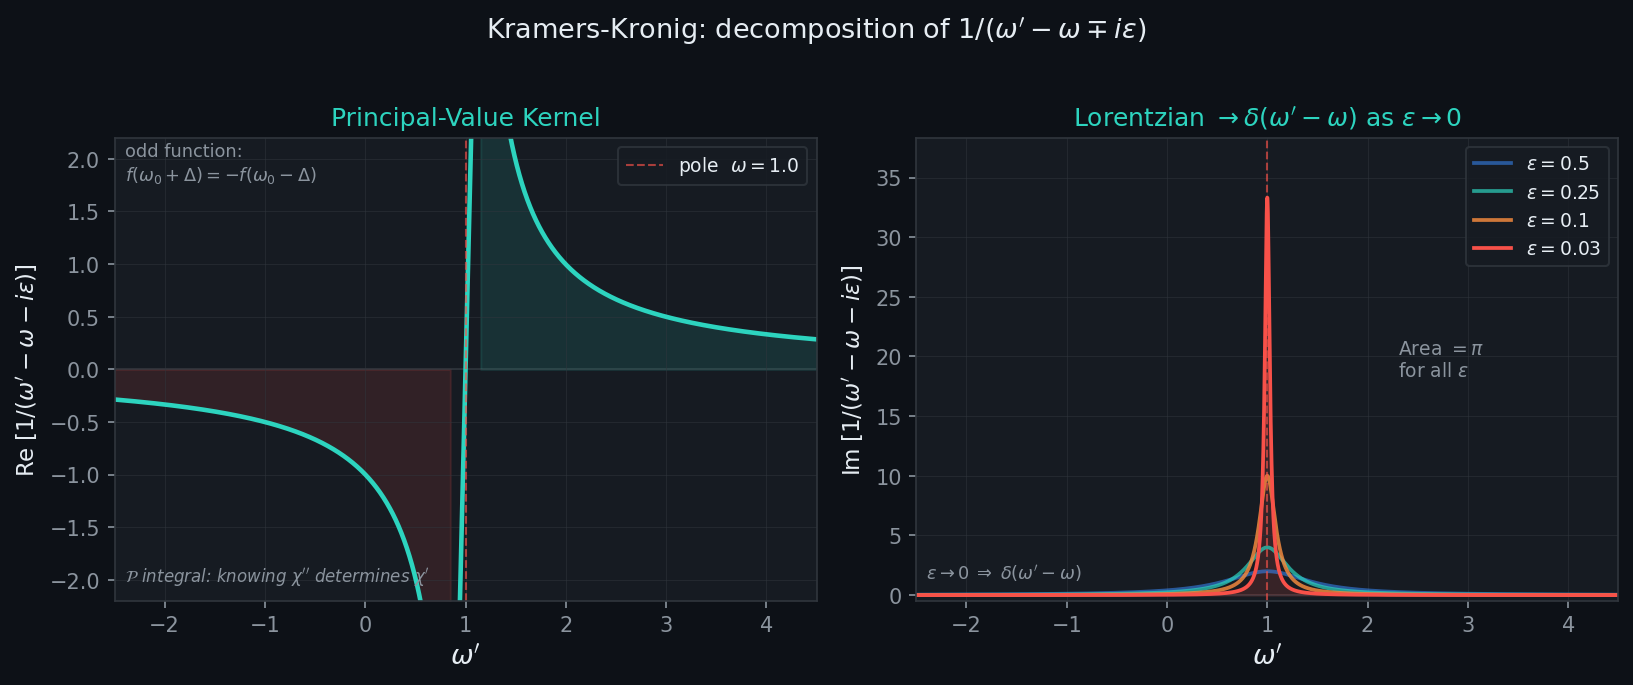


─── kt_fig_chi_harmonic.png ───


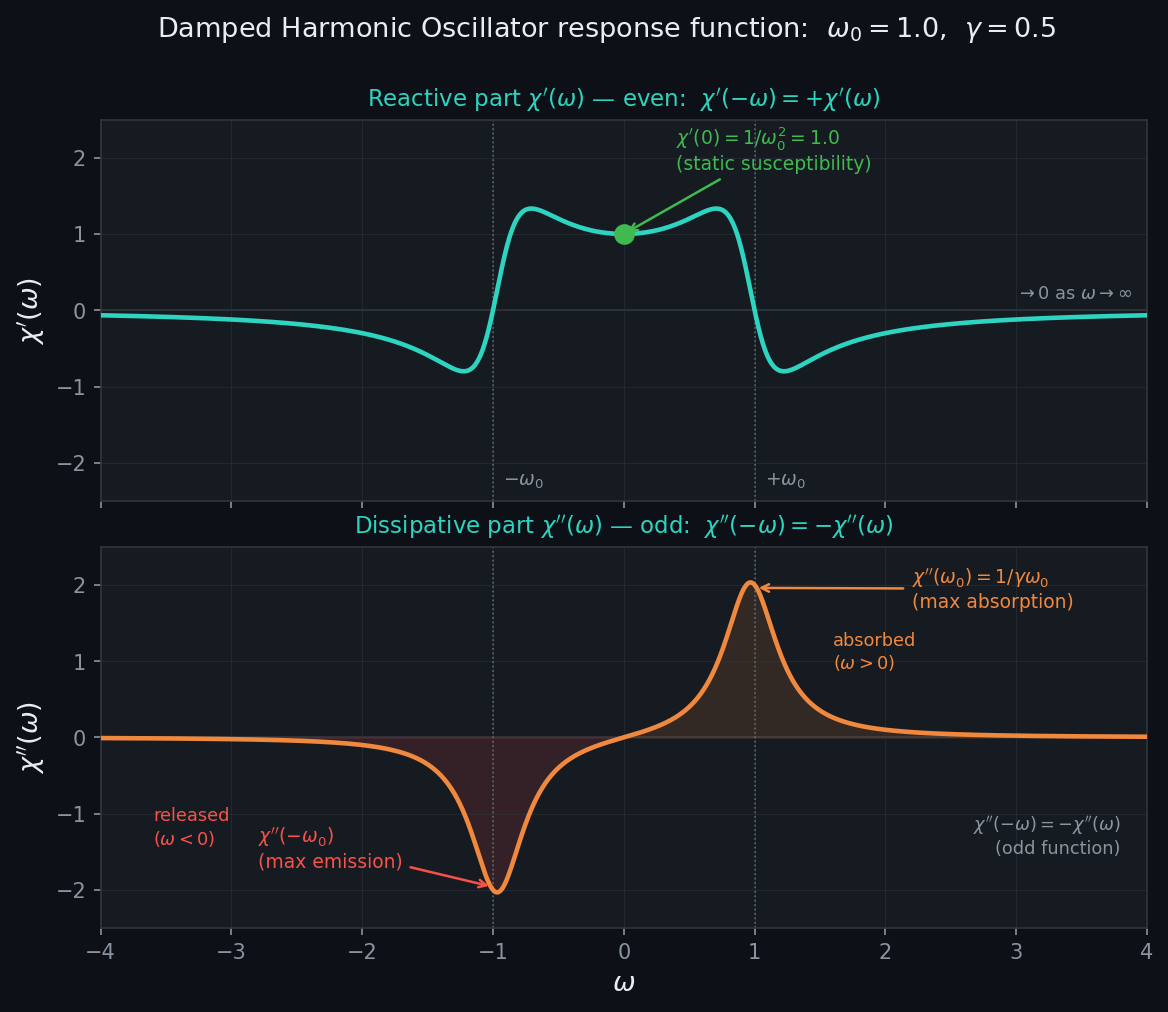


─── kt_fig_dissipation.png ───


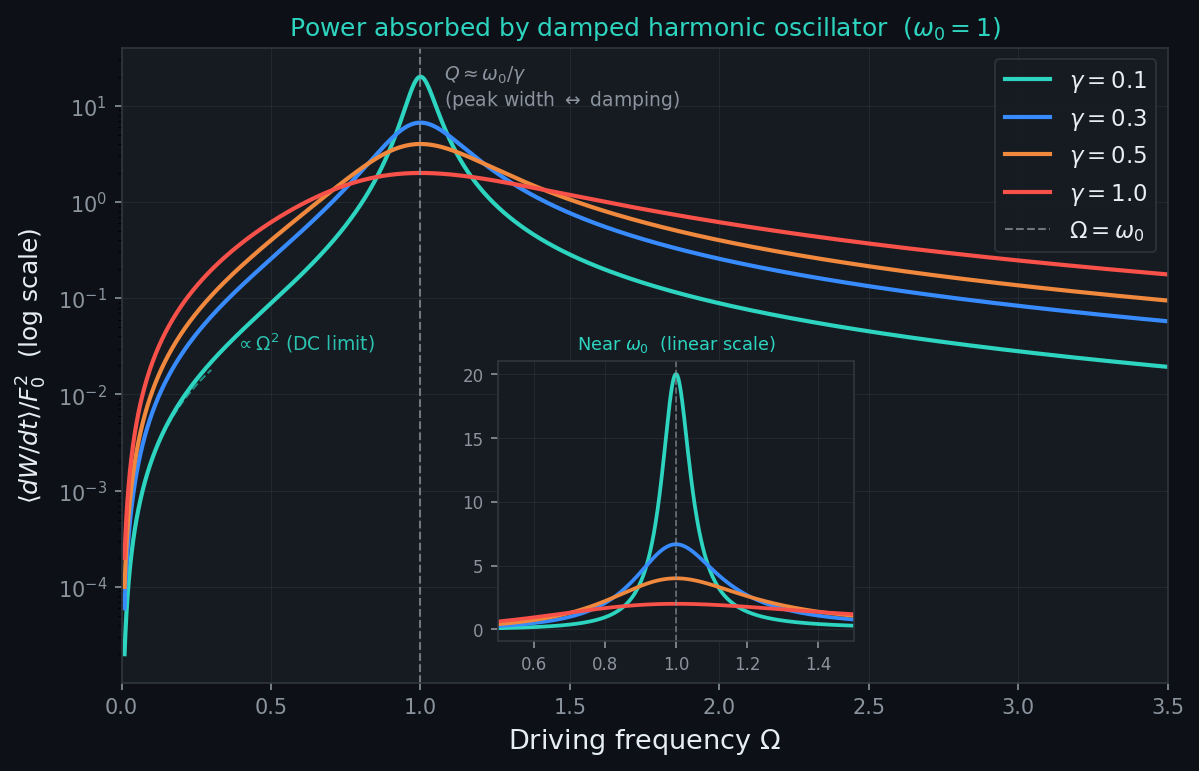


─── kt_fig_poles.png ───


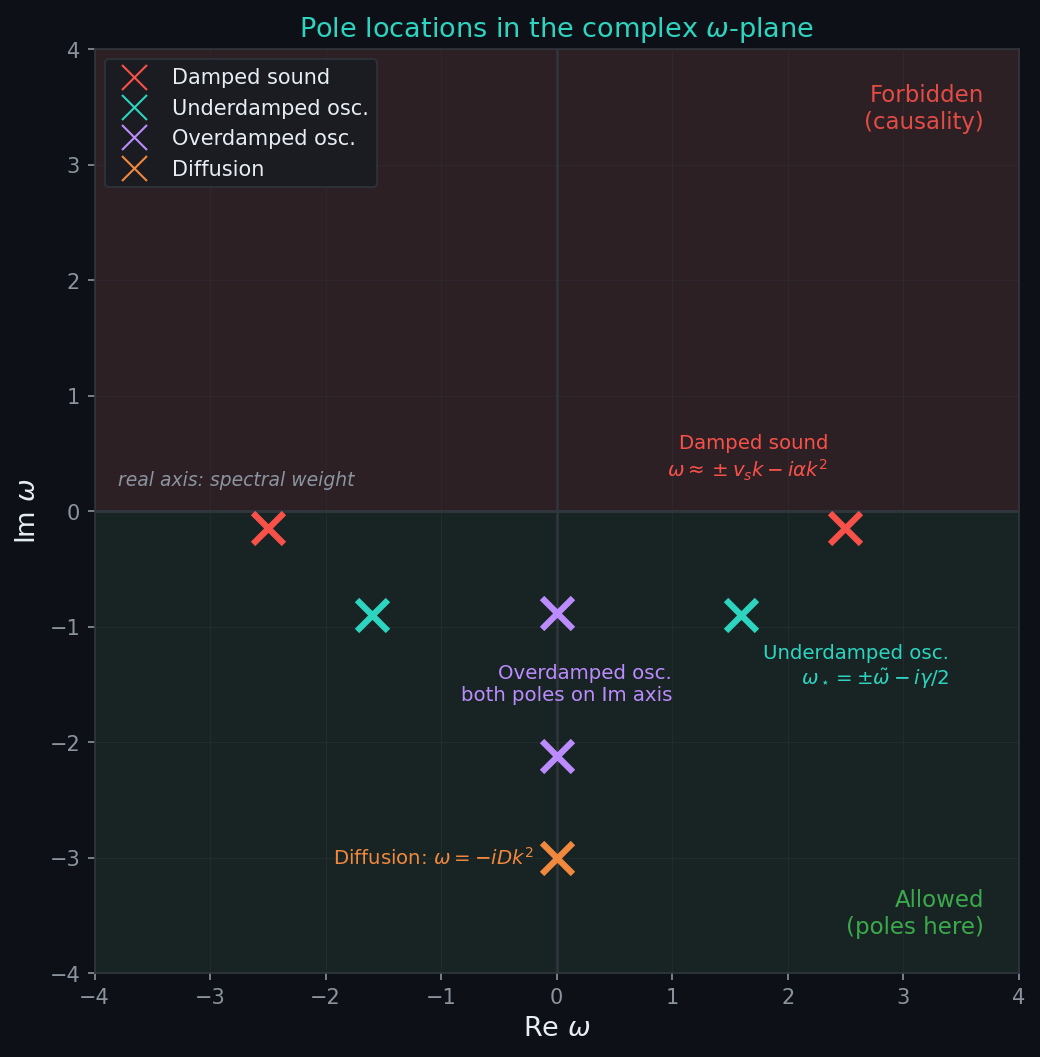


─── kt_fig_spectral.png ───


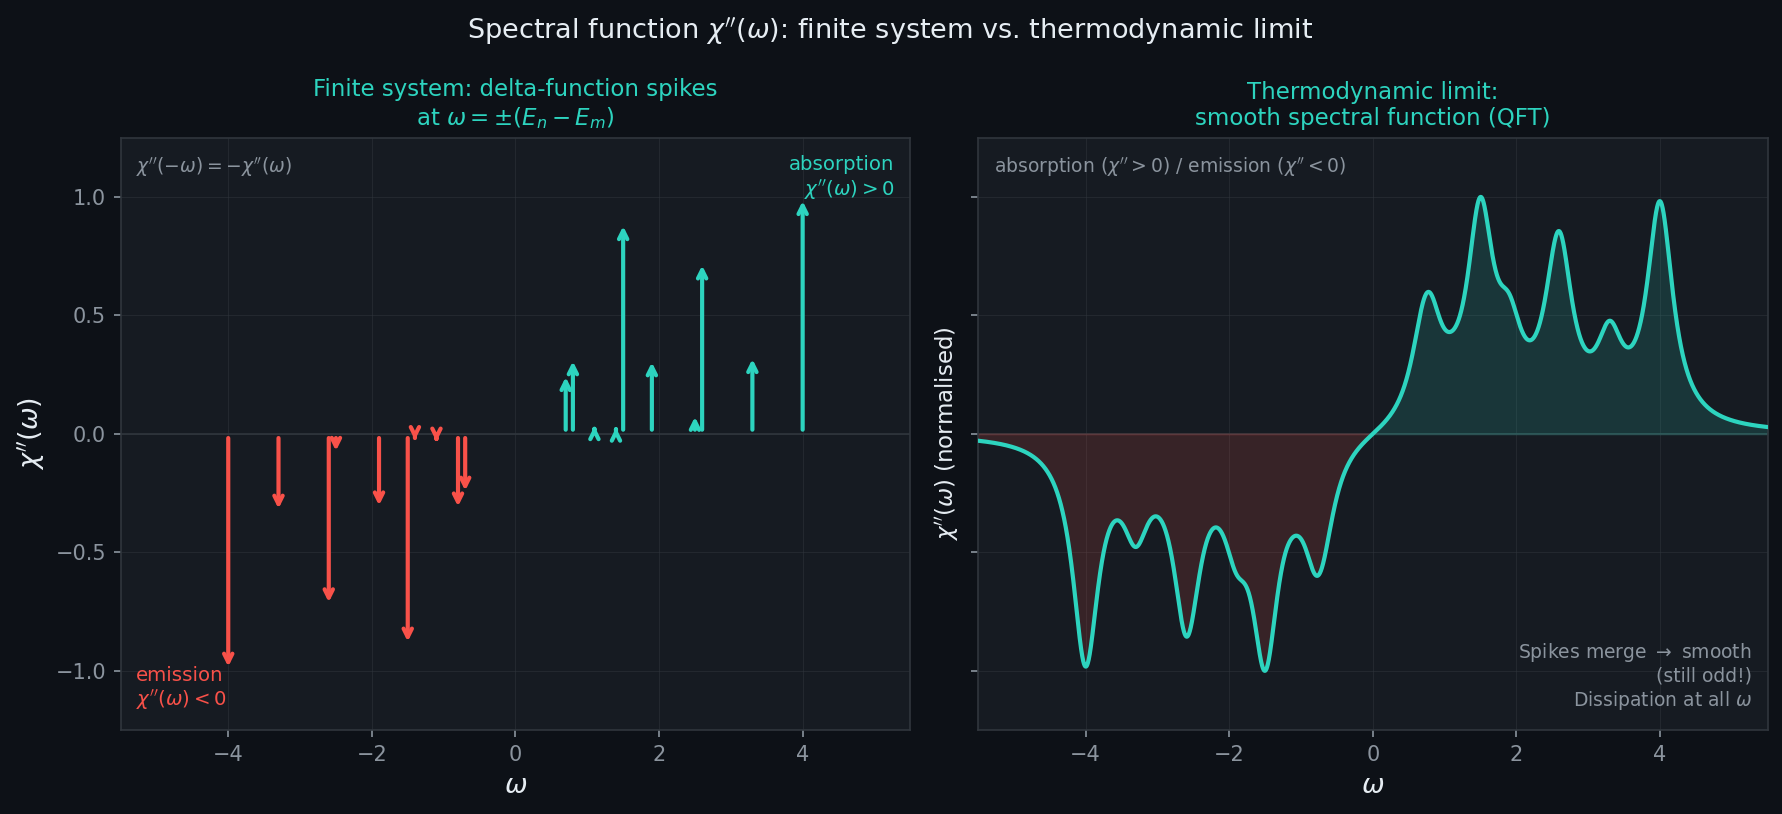

In [7]:
import os
from IPython.display import display, Image

expected = [
    'kt_fig_kramerskronig.png',
    'kt_fig_chi_harmonic.png',
    'kt_fig_dissipation.png',
    'kt_fig_poles.png',
    'kt_fig_spectral.png',
]

print('=== Figure files in figures/ ===')
all_ok = True
for fname in expected:
    path = f'figures/{fname}'
    if os.path.exists(path):
        kb = os.path.getsize(path) / 1024
        print(f'  ✓  {fname:42s}  ({kb:.1f} kB)')
    else:
        print(f'  ✗  {fname}  NOT FOUND')
        all_ok = False

if all_ok:
    print('\nAll figures generated successfully.\n')
    for fname in expected:
        print(f'\n─── {fname} ───')
        display(Image(f'figures/{fname}', width=720))
